# SS8 — Synthetic Software Log Analysis (JSONL)

**Academic demonstrator for SS7/SS8.** The timings in this notebook are **Python execution time (milliseconds)** for synthetic software workloads. They **are not human completion time (minutes)** and are not evidence of a Generative AI productivity effect. See `docs/SS8_DATA_PROCESSING.md` for definitions, limitations, and links to the human-task crossover study.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from process_ss7_logs import read_jsonl, mark_outliers, run_analysis
from visualize_ss7_logs import make_figures

SOURCE = ROOT / "data" / "sample" / "ss7_software_benchmark_demo.jsonl"
print("Input:", SOURCE)
print("This notebook uses only synthetic software execution times (ms).")

Input: /mnt/data/SS8_Data_Processing_Update/data/sample/ss7_software_benchmark_demo.jsonl
This notebook uses only synthetic software execution times (ms).


## 1. Ingestion, validation, warm-up and error auditing

Read the SS7 JSONL with one metadata event and 105 measurement events. Exclude warm-up from later summaries; keep failed benchmark runs in the error-rate denominator.

In [2]:
raw, env = read_jsonl(SOURCE)
print("All measurement records:", len(raw))
print("Warm-up:", (raw.phase == "warmup").sum())
print("Benchmark:", (raw.phase == "benchmark").sum())
print("Errors in benchmark:", ((raw.phase == "benchmark") & (raw.status == "error")).sum())
print("Operating system of original sample log:", env.get("environment", {}).get("os"))
display(raw[["phase", "workload_profile", "input_rows", "duration_ms", "status"]].head())

All measurement records: 105
Warm-up: 5
Benchmark: 100
Errors in benchmark: 0
Operating system of original sample log: Linux


,phase,workload_profile,input_rows,duration_ms,status
0,warmup,medium,16,23.651393,ok
1,warmup,small,8,22.762336,ok
2,warmup,small,8,21.489622,ok
3,warmup,small,8,21.484583,ok
4,warmup,medium,16,23.006994,ok


## 2. Non-destructive outliers and statistical aggregation

Within each input-row workload group, mark values outside `[Q1 − 1.5×IQR, Q3 + 1.5×IQR]`; do not remove observations. Use 10,000 bootstrap resamples (seed 42) for mean runtime 95% CI. Quantiles are for successful runs only. Failed runs contribute to the separate failure rate.

In [3]:
summary_path = ROOT / "data" / "processed" / "ss8_software_metrics_summary.csv"
detail_path = ROOT / "outputs" / "ss8" / "clean_software_measurements.csv"
audit_path = ROOT / "outputs" / "ss8" / "ss8_audit.json"
summary, detail, audit = run_analysis(SOURCE, summary_path, detail_path, audit_path,
                                      seed=42, resamples=10000)
print("Warm-up excluded:", audit["warmup_excluded"])
print("Benchmark observations:", audit["benchmark_kept"])
print("Failures:", audit["benchmark_failures"])
print("IQR flags retained:", audit["benchmark_iqr_outlier_flags_not_removed"])
display(summary[["group", "benchmark_runs", "failed_runs", "mean_ms", "median_ms", "p95_ms", "p99_ms", "bootstrap_mean_ci95_lower_ms", "bootstrap_mean_ci95_upper_ms"]].round(3))

Warm-up excluded: 5
Benchmark observations: 100
Failures: 0
IQR flags retained: 11


,group,benchmark_runs,failed_runs,mean_ms,median_ms,p95_ms,p99_ms,bootstrap_mean_ci95_lower_ms,bootstrap_mean_ci95_upper_ms
0,overall,100,0,24.058,22.938,31.273,35.736,23.422,24.749
1,large (32 rows),9,0,26.641,25.668,33.978,35.365,24.136,29.572
2,medium (16 rows),30,0,23.890,23.019,30.114,32.392,23.001,24.943
3,small (8 rows),61,0,23.759,22.677,29.119,34.340,22.999,24.627


## 3. Scientific figures — with physical units and uncertainty

Percentile curves are plotted versus **synthetic input rows**, not RPS. Error bars represent 95% percentile-bootstrap confidence intervals of successful software-run means. Boxplots retain all successful IQR-flagged observations. Plots are saved in vector PDF and 300-DPI PNG.

Figure assets:
- ss8_software_percentiles.png
- ss8_software_percentiles.pdf
- ss8_software_distribution.png
- ss8_software_distribution.pdf


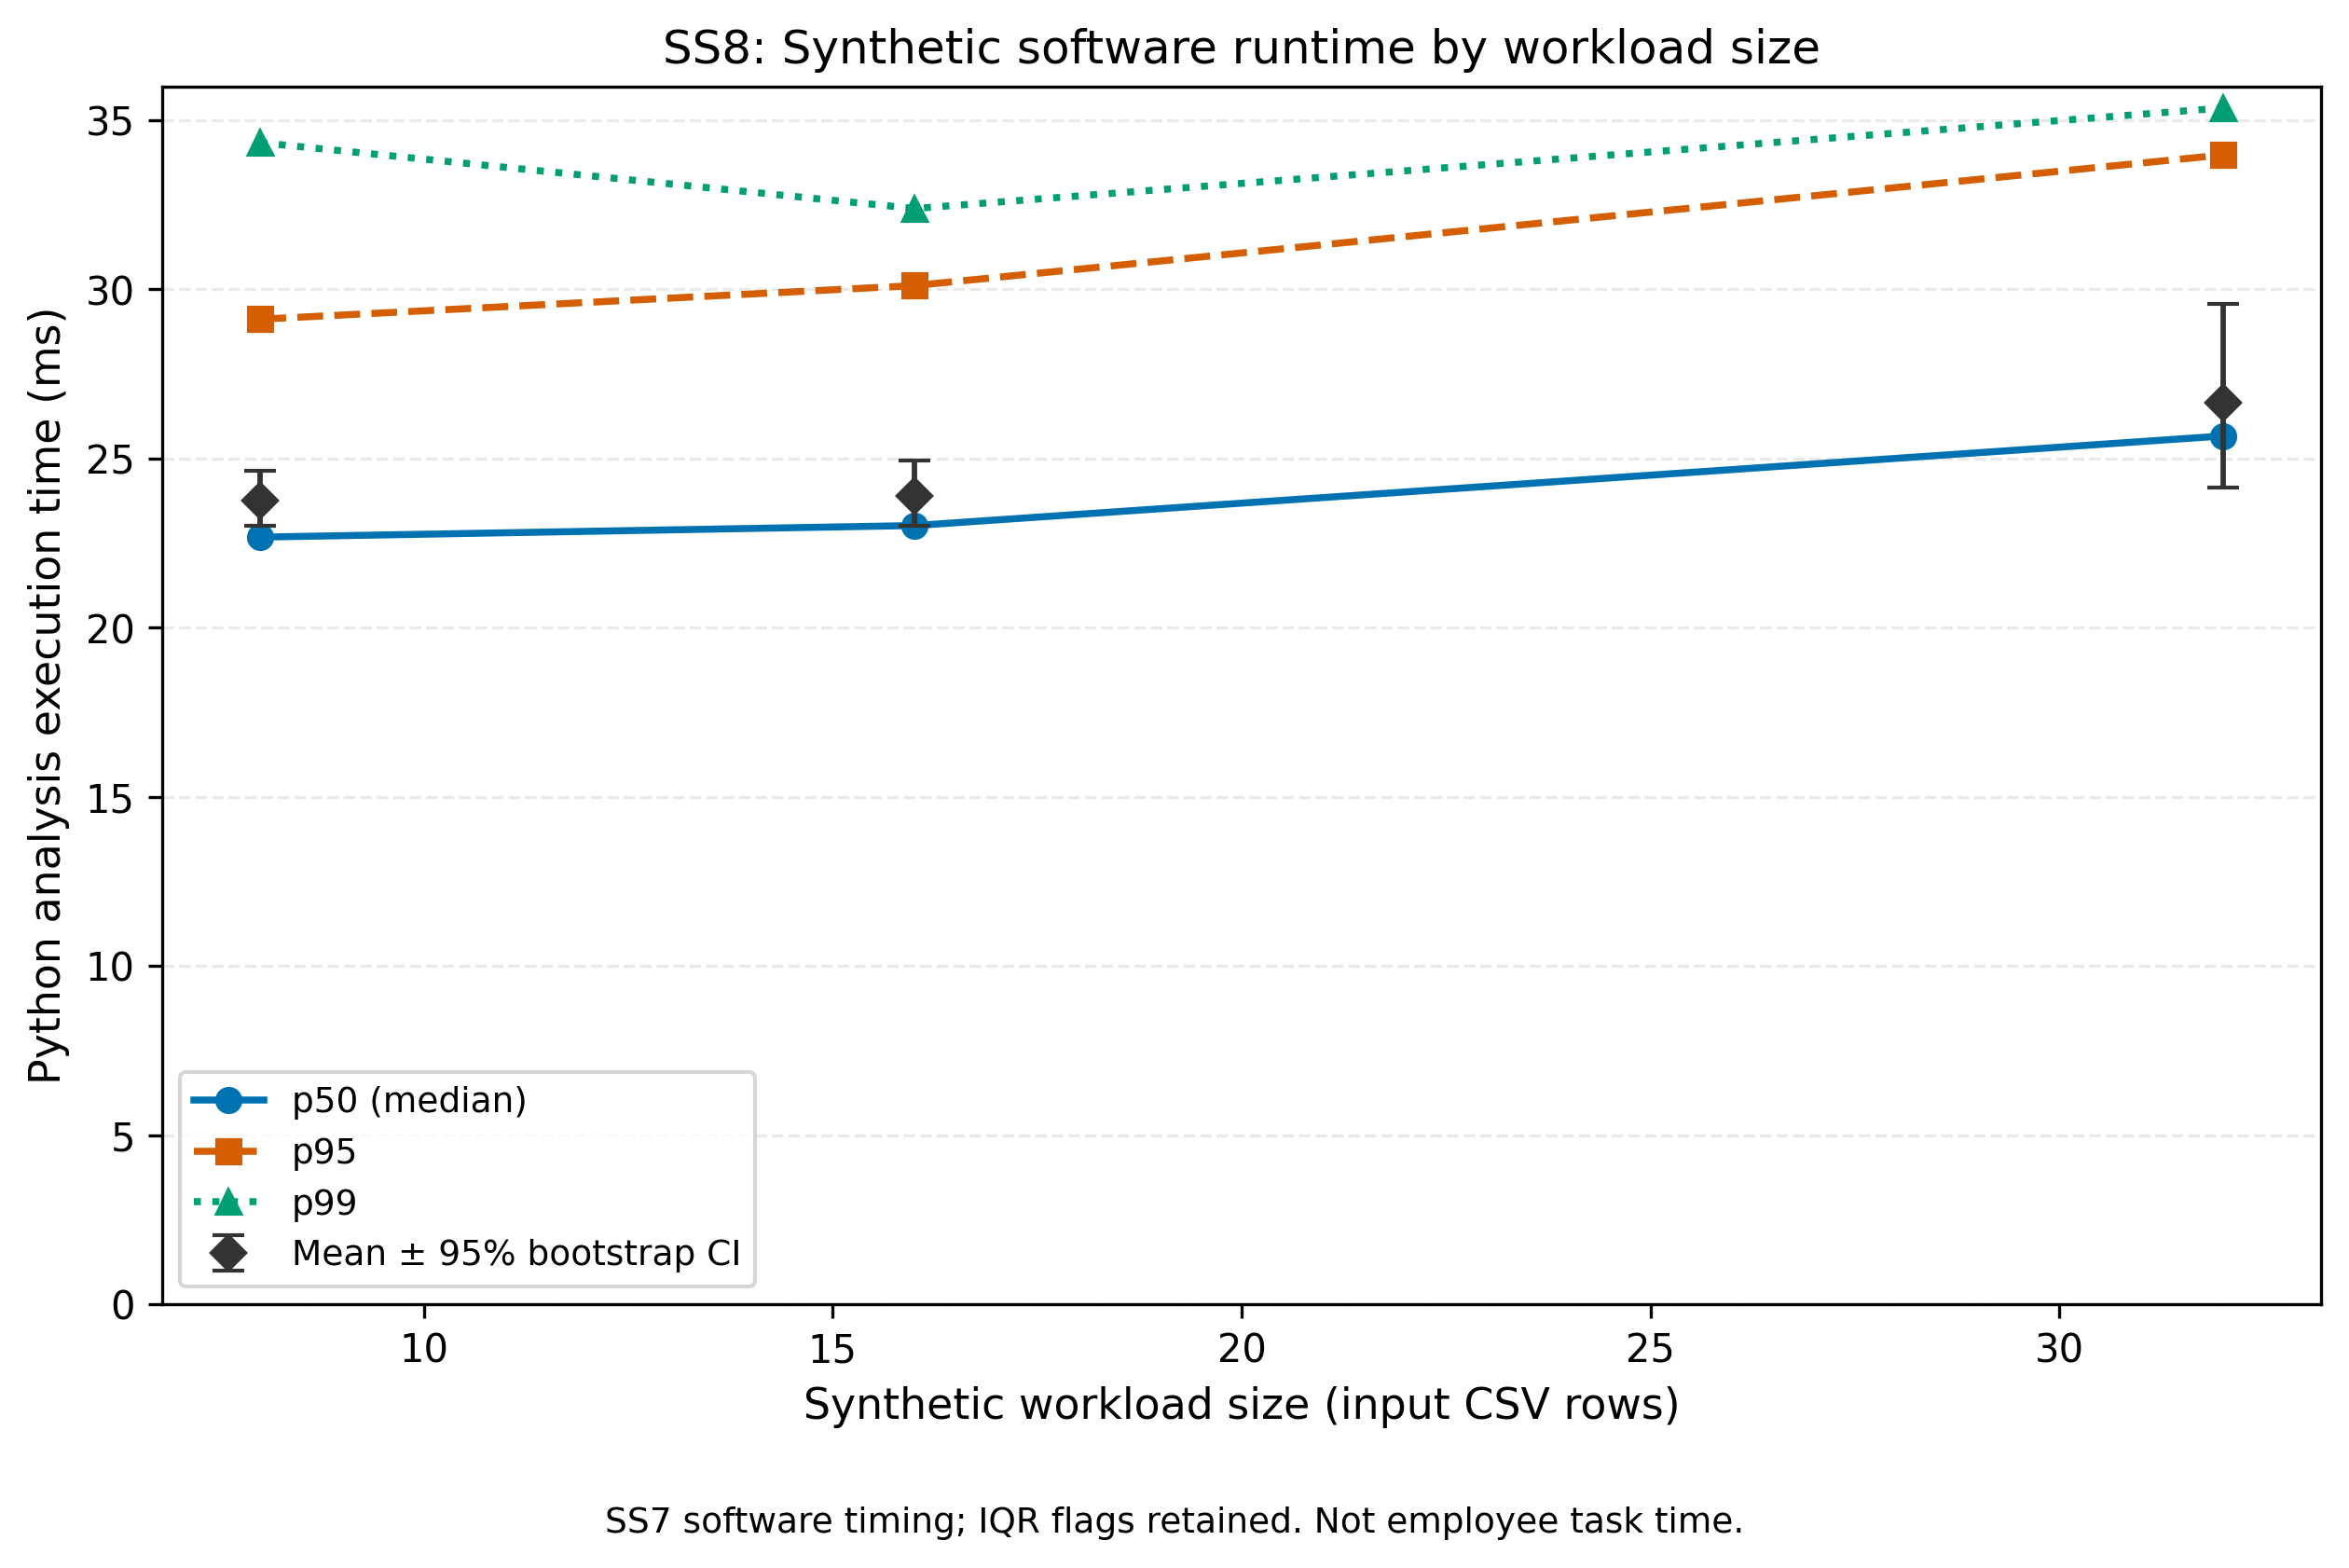

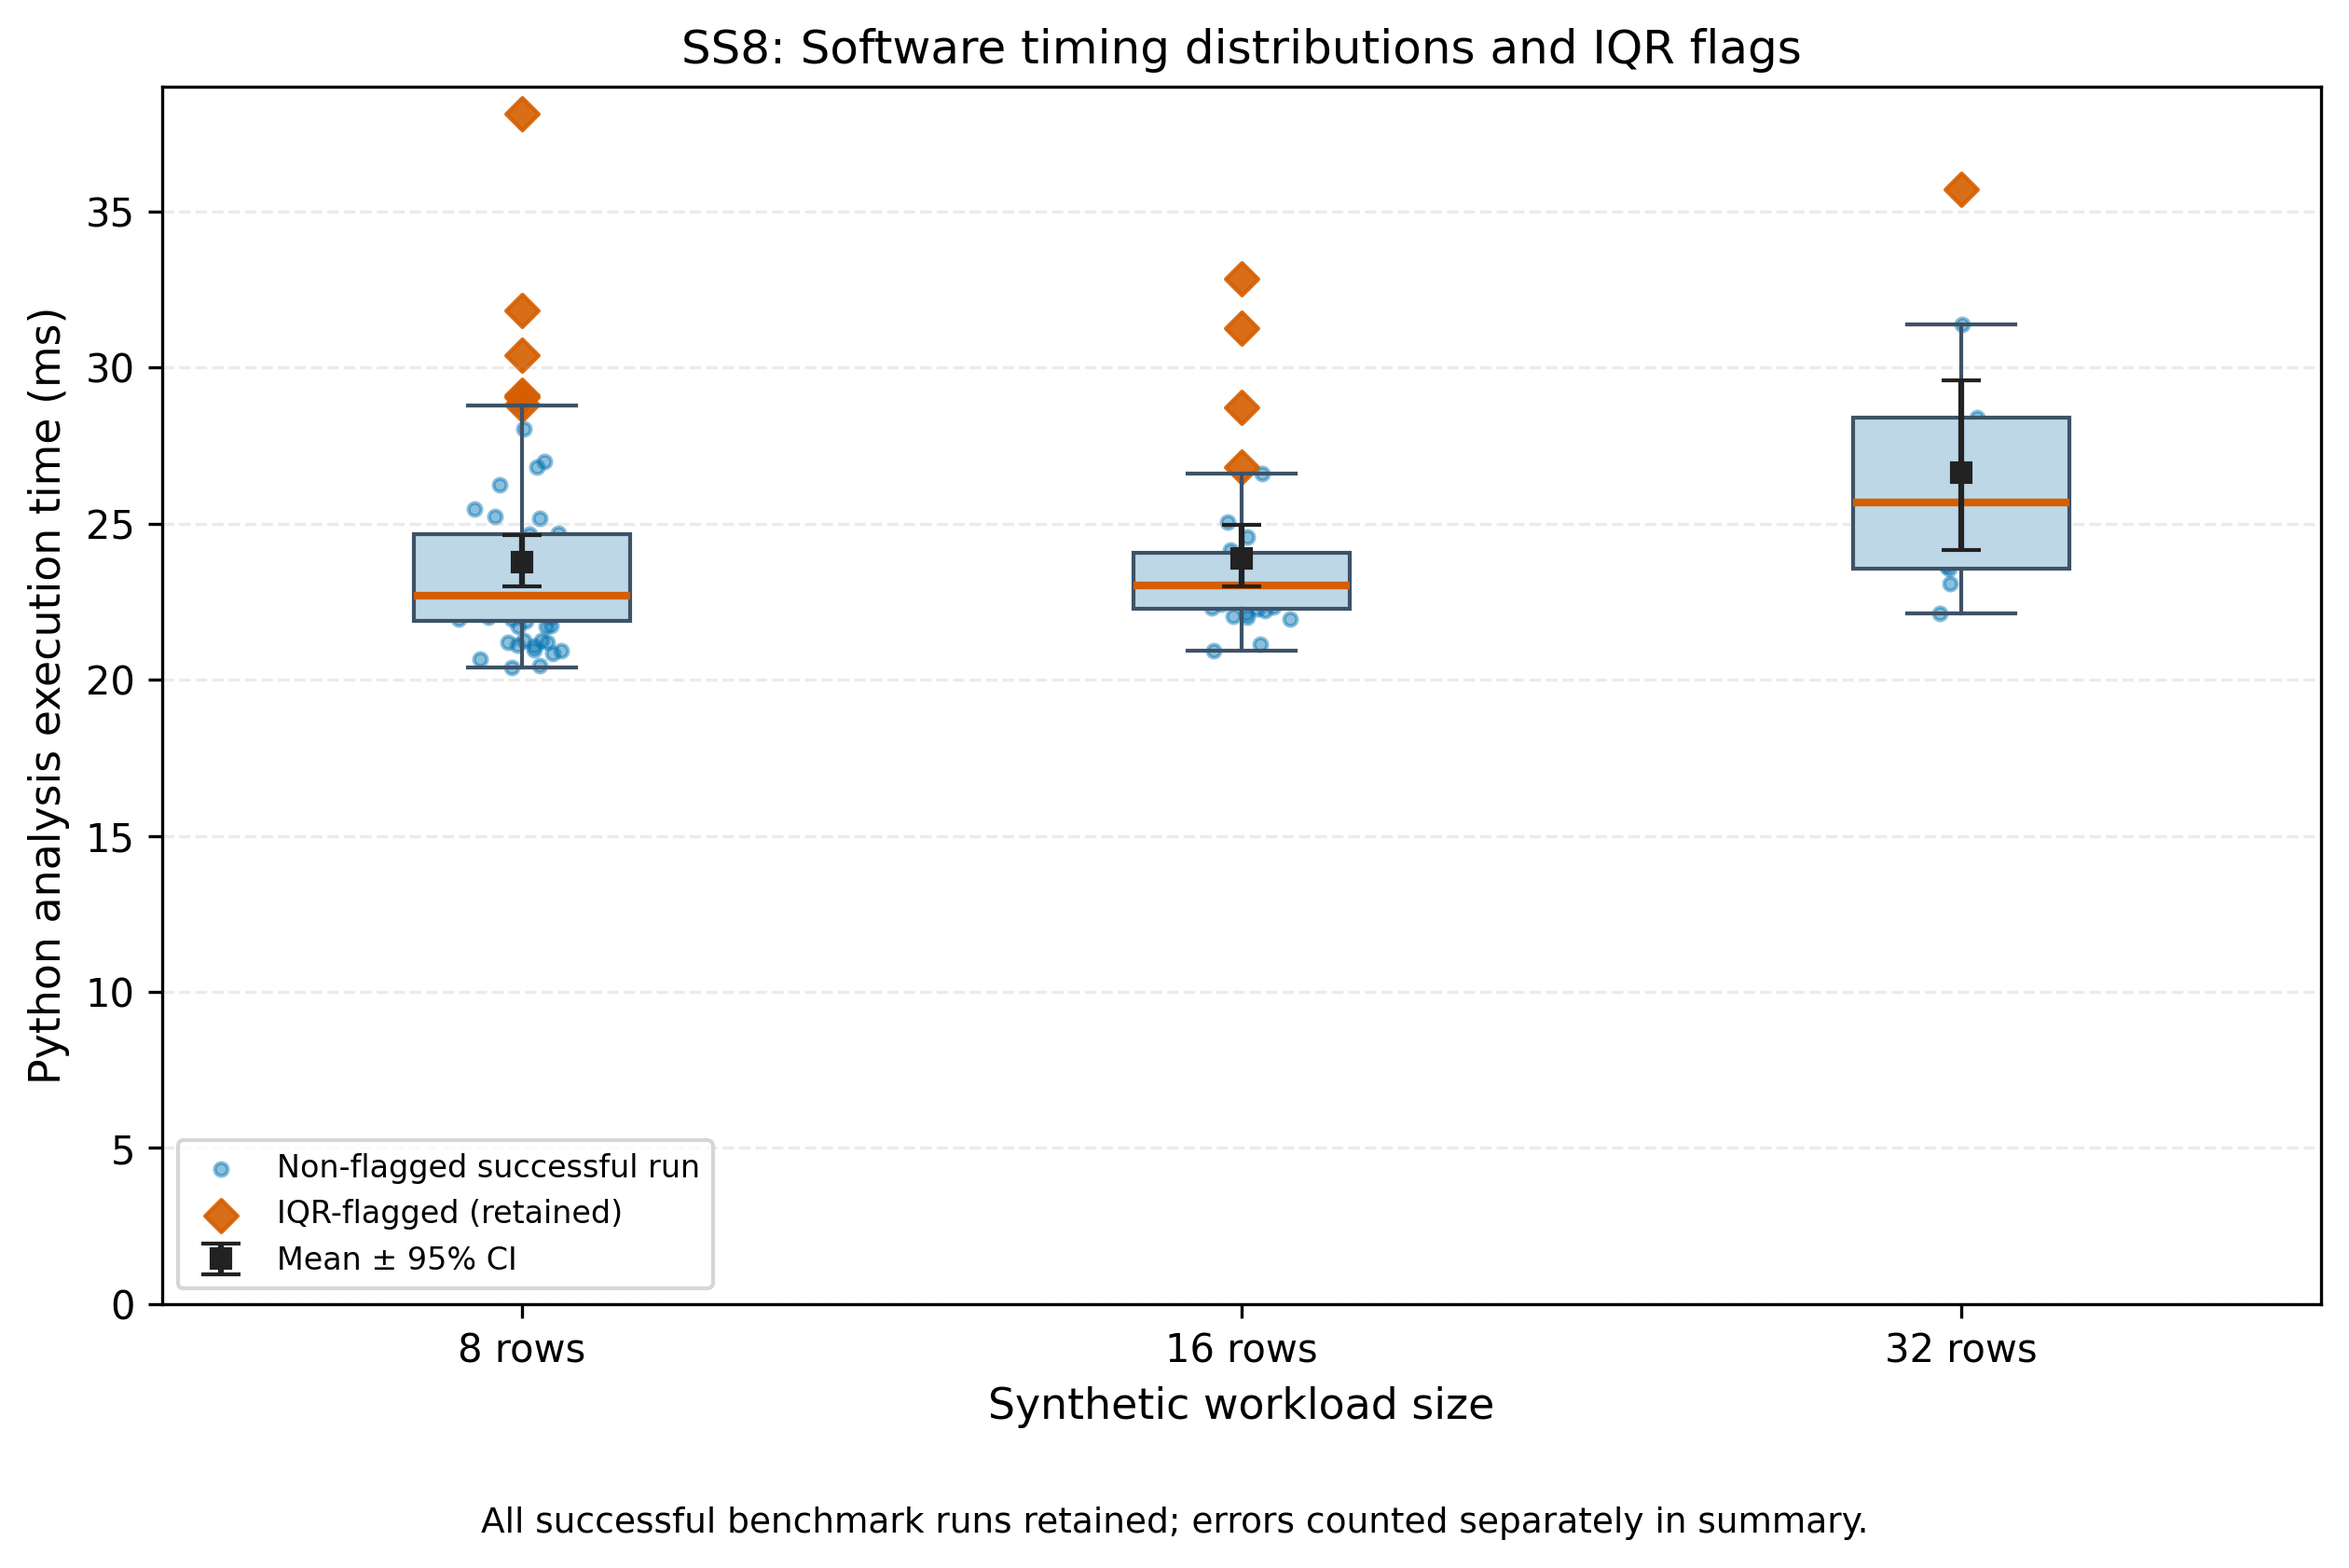

In [4]:
figure_dir = ROOT / "reports" / "figures"
figs = make_figures(summary, detail, figure_dir)
print("Figure assets:", *[f.name for f in figs], sep="\n- ")
display(Image(filename=str(figure_dir / "ss8_software_percentiles.png"), width=700))
display(Image(filename=str(figure_dir / "ss8_software_distribution.png"), width=700))

## 4. Interpretation and limits

The example dataset is a **synthetic software-pipeline benchmark**. It contains **5 warm-up** and **100 measured** runs, with failures separately recorded. Differences among workload sizes are descriptive and may be affected by CPU scheduling and other environmental factors. The software runtime CI does not establish a causal effect of GenAI on employee productivity. For human experiments, use the team's *separate* crossover pipeline, `notebooks/01_data_analysis.ipynb`, measured in minutes.